<a href="https://colab.research.google.com/github/nlp-usd/sdl_tatik_2026/blob/main/01_Colab_Latih_Tuning_Trace_PWA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BASA JAWA Edge — Latih, tuning, telusuri, dan ekspor
Notebook utama untuk siswa SMA dengan pendamping. Gunakan CPU Colab. Dataset sekunder sudah dibundel; tidak perlu membuat korpus baru.

Tiga keluarga classifier: Logistic Regression, Linear SVM, dan Multinomial Naive Bayes. Lima pengaturan fitur dikombinasikan dengan tiga nilai parameter tiap classifier, sehingga ada **45 percobaan**. Model dipilih memakai validasi dan batas JSON 512 KiB yang ditetapkan sebelum test. PWA melakukan prediksi di perangkat pengguna.

**Berkas yang harus disimpan:** protokol, manifest lingkungan/kode, partisi, tabel tuning, keputusan pemilihan, prediksi test, trace fitur, model terpilih, dan rilis PWA. Hasil yang muncul adalah hasil runtime Anda. Jangan memakai angka contoh sebagai hasil Colab.


## 1 Hubungkan notebook dengan kode GitHub
Unggah isi paket awal ke repositori GitHub, lalu ubah REPO_URL. Notebook yang dibuka melalui GitHub tidak otomatis membawa seluruh berkas proyek ke runtime; sel ini melakukan clone. Untuk percobaan awal tanpa repositori, gunakan MODE="upload_zip" dan unggah ZIP paket.

Jalankan setiap sel berurutan. Bila ingin melihat kode fungsi, buka `src/lab.py` di panel Files atau GitHub. Nama fungsi mengikuti tahapan notebook.


In [1]:

import os,sys,subprocess,re,json
from pathlib import Path
for name in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[name]='1'
# Isi alamat repositori publik Anda setelah mengunggah paket awal ke GitHub.
REPO_URL = "https://github.com/TeresaHertada/basa-jawa-edge.git"
REPO_REF = "main"   # Untuk mengulang persis, ganti dengan commit SHA yang telah dicatat.
MODE = "github"     # Pilihan lain: "upload_zip" bila repositori belum dibuat.
if os.environ.get("BASA_REPO_ROOT"):
    ROOT = Path(os.environ["BASA_REPO_ROOT"]).resolve()  # pemeriksaan lokal oleh pengembang
elif MODE == "github":
    if not re.fullmatch(r"https://github\.com/[A-Za-z0-9_.-]+/[A-Za-z0-9_.-]+(?:\.git)?",REPO_URL) or "USERNAME" in REPO_URL:
        raise ValueError("Ganti REPO_URL dengan repositori GitHub Anda, lalu jalankan sel ini lagi.")
    ROOT = Path("/content/basa-jawa-edge")
    if not ROOT.exists():subprocess.run(["git","clone",REPO_URL,str(ROOT)],check=True)
    subprocess.run(["git","-C",str(ROOT),"fetch","origin"],check=True)
    resolved_ref='origin/main' if REPO_REF=='main' else REPO_REF
    # Detached checkout mengunci sumber pada commit yang benar-benar diambil.
    # Git akan berhenti bila ada perubahan lokal yang bertabrakan; tidak ada reset otomatis.
    subprocess.run(["git","-C",str(ROOT),"checkout","--detach",resolved_ref],check=True)
else:
    from google.colab import files
    import zipfile
    uploads=files.upload()
    archive=next((name for name in uploads if name.endswith('.zip')),None)
    if archive is None:raise ValueError("Pilih ZIP paket repositori.")
    target=Path('/content/basa_upload');target.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            path=(target/member.filename).resolve()
            if not path.is_relative_to(target.resolve()):raise ValueError('Path ZIP tidak aman')
        z.extractall(target)
    matches=list(target.rglob('protocol/experiment.json'))
    if len(matches)!=1:raise ValueError('ZIP harus memuat satu folder proyek')
    ROOT=matches[0].parent.parent
assert (ROOT/'src/lab.py').exists(), ROOT
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
print('Folder proyek:',ROOT)


Folder proyek: /content/basa-jawa-edge


## 2 Siapkan pustaka sebelum mengimpor model
Sel ini hanya memasang pustaka utama bila versinya berbeda. Versi semua pustaka yang benar-benar digunakan akan dicatat ke manifest.


In [2]:
import importlib.metadata
for name in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[name]='1'  # Tetapkan sebelum NumPy/scikit-learn diimpor.
wanted={'scikit-learn':'1.8.0','joblib':'1.5.3','threadpoolctl':'3.6.0'}
needed=[]
for package,version in wanted.items():
    try:installed=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:installed=None
    if installed!=version:needed.append(f'{package}=={version}')
if needed:subprocess.run([sys.executable,'-m','pip','install','-q',*needed],check=True)
import numpy as np,pandas as pd,sklearn
try:
    from IPython.display import display,Image
except ImportError:
    def display(value):print(value)
    def Image(filename):return filename
from src import lab
if sklearn.__version__!='1.8.0':raise RuntimeError('Restart runtime, lalu jalankan lagi dari sel pertama.')
print('Python',sys.version.split()[0],'| scikit-learn',sklearn.__version__,'| NumPy',np.__version__)


Python 3.13.18 | scikit-learn 1.8.0 | NumPy 2.4.6


## 3 Kunci protokol sebelum melihat hasil test
Baca parameter dan aturan pemilihan. Perubahan parameter dilakukan di `protocol/experiment.json`, disimpan sebagai commit, lalu dicatat pada run baru. Test tidak digunakan untuk memilih konfigurasi. Batas 512 KiB adalah batas desain paket JSON, bukan klaim batas memori smartphone.


In [3]:
CONFIG=json.loads((ROOT/'protocol/experiment.json').read_text())
print(json.dumps(CONFIG,indent=2,ensure_ascii=False))
RUN,RUN_META=lab.start_run(ROOT,CONFIG,run_id=os.environ.get('BASA_RUN_ID'))
print('Run ID:',RUN_META['run_id'])
print('Commit:',RUN_META['source_git_commit'])
print('Hash kode:',RUN_META['training_code_sha256'])
print('Semua hasil disimpan di:',RUN)


{
  "seed_test": 42,
  "seed_validation": 43,
  "test_fraction": 0.2,
  "validation_fraction_of_remaining": 0.25,
  "features": [
    {
      "name": "word_full",
      "analyzer": "word",
      "max_features": null
    },
    {
      "name": "char_full",
      "analyzer": "char",
      "max_features": null
    },
    {
      "name": "char_1024",
      "analyzer": "char",
      "max_features": 1024
    },
    {
      "name": "char_2048",
      "analyzer": "char",
      "max_features": 2048
    },
    {
      "name": "char_4096",
      "analyzer": "char",
      "max_features": 4096
    }
  ],
  "C_values": [
    0.5,
    2.0,
    4.0
  ],
  "alpha_values": [
    0.1,
    0.5,
    1.0
  ],
  "model_json_budget_bytes": 524288,
  "validation_tolerance": 0.01,
  "selection": "Among candidates under the JSON budget and within the tolerance of the best eligible validation macro-F1, choose the smallest model JSON; tie-break by validation macro-F1 then trial ID.",
  "training_scope": "Fit vocab

## 4 Audit dataset dan makna label
Hash memeriksa bahwa berkas sama dengan snapshot yang ditetapkan. `translation.csv` menyediakan kalimat Jawa dan label, sedangkan `conversation.csv` menjadi materi dialog. Label bersumber dari peneliti asli. Tabel awal hanya audit, bukan hasil prediksi model.


In [4]:
ROWS,DIALOGUES=lab.load_snapshot(ROOT,CONFIG,RUN)
DATA_HASH=lab.digest(ROOT/'data/translation.csv')
display(pd.DataFrame(ROWS).head(8))
display(pd.DataFrame([{'label':i,'nama':name,'baris':sum(int(r['label'])==i for r in ROWS)} for i,name in lab.LABELS.items()]))
print('Kalimat:',len(ROWS),'Dialog:',len(DIALOGUES),'Hash:',DATA_HASH)


,index,label,javanese sentence,group,indonesian sentence,english sentence
0,0,0,Nggawaa jeruk kuwi!,1,Membawalah jeruk itu.,Bring that orange.
1,1,1,Panjenengan ngampil jeruk kuwi!,1,Membawalah jeruk itu.,Bring that orange.
2,2,2,Sampeyan mbekta jeram menika!,1,Membawalah jeruk itu.,Bring that orange.
3,3,3,Panjenengan ngampil jeram menika!,1,Membawalah jeruk itu.,Bring that orange.
4,4,0,"Tustele rusak, digawaa ya ora ana gunane.",2,"Tustelnya rusak, seandainya dibawa tidak ada g...","The camera is broken, so there's no point in b..."
5,5,1,"Tustele rusak, diampila ya ora ana gunane.",2,"Tustelnya rusak, seandainya dibawa tidak ada g...","The camera is broken, so there's no point in b..."
6,6,2,"Tustelipun risak, dipunbektaa inggih boten won...",2,"Tustelnya rusak, seandainya dibawa tidak ada g...","The camera is broken, so there's no point in b..."
7,7,3,"Tustelipun risak, dipunampila inggih boten won...",2,"Tustelnya rusak, seandainya dibawa tidak ada g...","The camera is broken, so there's no point in b..."


,label,nama,baris
0,0,Ngoko,742
1,1,Ngoko Alus,263
2,2,Krama,740
3,3,Krama Alus,264


Kalimat: 2009 Dialog: 80 Hash: fadfdfe3473a5d2bb52112d93828e1bb762ed6d1d38dc3577d2928a7612f2e6c


## 5 Pisahkan keluarga kalimat sebelum pelatihan
`safe_groups` menyatukan group dan kalimat paralel yang identik setelah normalisasi. Model tidak boleh belajar satu versi kalimat lalu diuji pada versi tingkat tutur lain dari keluarga yang sama. Semua perhitungan kosakata dan IDF hanya memakai train. `partitions.csv` menyimpan identitas baris sehingga pembagian bisa dilacak.


In [5]:
PARTS,GROUPS=lab.partition(ROWS,CONFIG,RUN)
display(pd.DataFrame([{'partisi':name,'baris':len(ids),'komponen_grup':len(set(GROUPS[ids]))} for name,ids in PARTS.items()]))
print('Irisan grup kosong: diperiksa dengan assert di lab.partition.')
# Buka fungsi jika ingin menelusuri proses pembagian:
import inspect
print(inspect.getsource(lab.partition))


,partisi,baris,komponen_grup
0,train,1199,447
1,validation,396,149
2,test,414,149


Irisan grup kosong: diperiksa dengan assert di lab.partition.
def partition(rows,config,run=None):
    groups=safe_groups(rows);labels=np.array([int(r['label']) for r in rows])
    splitter=GroupShuffleSplit(n_splits=1,test_size=config['test_fraction'],random_state=config['seed_test'])
    development,test=next(splitter.split(rows,labels,groups))
    splitter=GroupShuffleSplit(n_splits=1,test_size=config['validation_fraction_of_remaining'],random_state=config['seed_validation'])
    train,validation=next(splitter.split(development,groups=groups[development]))
    parts={'train':development[train],'validation':development[validation],'test':test}
    sets=[set(groups[ids]) for ids in parts.values()]
    assert len(set.union(*sets))==sum(len(s) for s in sets)
    assert all(set(labels[ids])==set(LABELS) for ids in parts.values())
    if run:
        write_csv(Path(run)/'partitions.csv',[dict(row_index=int(i),source_index=rows[int(i)]['index'],
            group_component=int(groups[i]),p

## 6 Definisikan percobaan dan baseline
Tabel berikut adalah seluruh rencana percobaan. `C` mengatur regularisasi LR/SVM; `alpha` mengatur smoothing Naive Bayes. Mulai dari baseline kata + LR dengan C=4 agar alur fit dan validasi terlihat sebelum tuning.


In [6]:
SPECS=lab.trial_specs(CONFIG)
display(pd.DataFrame([{'trial':s['trial_id'],'fitur':s['feature']['name'],'keluarga':s['family'],s['parameter_name']:s['parameter_value']} for s in SPECS]))
BASELINE=next(s for s in SPECS if s['family']=='logistic_regression' and s['feature']['name']=='word_full' and s['parameter_value']==4)
BASE_MODEL,BASE_RECORD=lab.fit_trial(BASELINE,ROWS,PARTS,CONFIG,RUN_META,DATA_HASH)
print('Baseline:',BASE_RECORD)
print(BASE_MODEL)
print(inspect.getsource(lab.make_pipeline))
print(inspect.getsource(lab.fit_trial))


,trial,fitur,keluarga,C,alpha
0,T001,word_full,logistic_regression,0.5,NaN
1,T002,word_full,logistic_regression,2.0,NaN
2,T003,word_full,logistic_regression,4.0,NaN
3,T004,word_full,linear_svm,0.5,NaN
4,T005,word_full,linear_svm,2.0,NaN
5,T006,word_full,linear_svm,4.0,NaN
6,T007,word_full,multinomial_nb,NaN,0.1
7,T008,word_full,multinomial_nb,NaN,0.5
8,T009,word_full,multinomial_nb,NaN,1.0
9,T010,char_full,logistic_regression,0.5,NaN


Baseline: {'trial_id': 'T003', 'family': 'logistic_regression', 'feature': 'word_full', 'parameter_name': 'C', 'parameter_value': 4.0, 'validation_macro_f1': 0.9139536640921933, 'validation_accuracy': 0.9393939393939394, 'features': 8715, 'model_json_bytes': 1041663, 'eligible': False, 'fit_seconds': 0.31980060400019283}
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=4.0, class_weight='balanced',
                                    max_iter=1500, random_state=42))])
def make_pipeline(spec):
    feature=spec['feature'];char=feature['analyzer']=='char'
    tf=TfidfVectorizer(analyzer=feature['analyzer'],ngram_range=(2,5) if char else (1,2),
        min_df=2 if char else 1,sublinear_tf=True,max_features=feature['max_features'])
    value=spec['parameter_value'];family=spec['family']
    if family=='logistic_regression':clf=LogisticRegression(C=value,max_iter=1500,class

## 7 Jalankan tuning dan simpan setiap percobaan
Baca loop ini: buat pipeline, fit train, prediksi validation, hitung macro-F1, ukur JSON, lalu tulis hasil. Tidak ada prediksi test di fungsi `fit_trial`. Angka durasi berasal dari runtime Colab dan tidak menggambarkan kecepatan smartphone.


T001 logistic_regression word_full val F1=0.9200 JSON=1032.9 KiB eligible= False
T002 logistic_regression word_full val F1=0.9130 JSON=1020.8 KiB eligible= False
T003 logistic_regression word_full val F1=0.9140 JSON=1017.2 KiB eligible= False
T004 linear_svm word_full val F1=0.8941 JSON=978.9 KiB eligible= False
T005 linear_svm word_full val F1=0.8941 JSON=930.0 KiB eligible= False
T006 linear_svm word_full val F1=0.9082 JSON=919.2 KiB eligible= False
T007 multinomial_nb word_full val F1=0.8866 JSON=962.9 KiB eligible= False
T008 multinomial_nb word_full val F1=0.7757 JSON=960.7 KiB eligible= False
T009 multinomial_nb word_full val F1=0.6229 JSON=960.8 KiB eligible= False
T010 logistic_regression char_full val F1=0.9512 JSON=2204.1 KiB eligible= False
T011 logistic_regression char_full val F1=0.9528 JSON=2182.0 KiB eligible= False
T012 logistic_regression char_full val F1=0.9528 JSON=2174.5 KiB eligible= False
T013 linear_svm char_full val F1=0.9488 JSON=2123.1 KiB eligible= False
T014

,trial_id,family,feature,parameter_name,parameter_value,validation_macro_f1,validation_accuracy,features,model_json_bytes,eligible,fit_seconds
11,T012,logistic_regression,char_full,C,4.0,0.952821,0.964646,19543,2226692,False,0.979553
10,T011,logistic_regression,char_full,C,2.0,0.952821,0.964646,19543,2234335,False,0.886031
39,T040,linear_svm,char_4096,C,0.5,0.952821,0.964646,4096,458285,True,0.267312
9,T010,logistic_regression,char_full,C,0.5,0.951164,0.962121,19543,2256991,False,0.849866
12,T013,linear_svm,char_full,C,0.5,0.948794,0.962121,19543,2174015,False,0.269304
14,T015,linear_svm,char_full,C,4.0,0.948794,0.962121,19543,2089788,False,0.379532
42,T043,multinomial_nb,char_4096,alpha,0.1,0.947735,0.959596,4096,433455,True,0.231207
30,T031,linear_svm,char_2048,C,0.5,0.947496,0.959596,2048,227029,True,0.287281
29,T030,logistic_regression,char_2048,C,4.0,0.946535,0.959596,2048,224664,True,0.370006
28,T029,logistic_regression,char_2048,C,2.0,0.946535,0.959596,2048,225781,True,0.353524


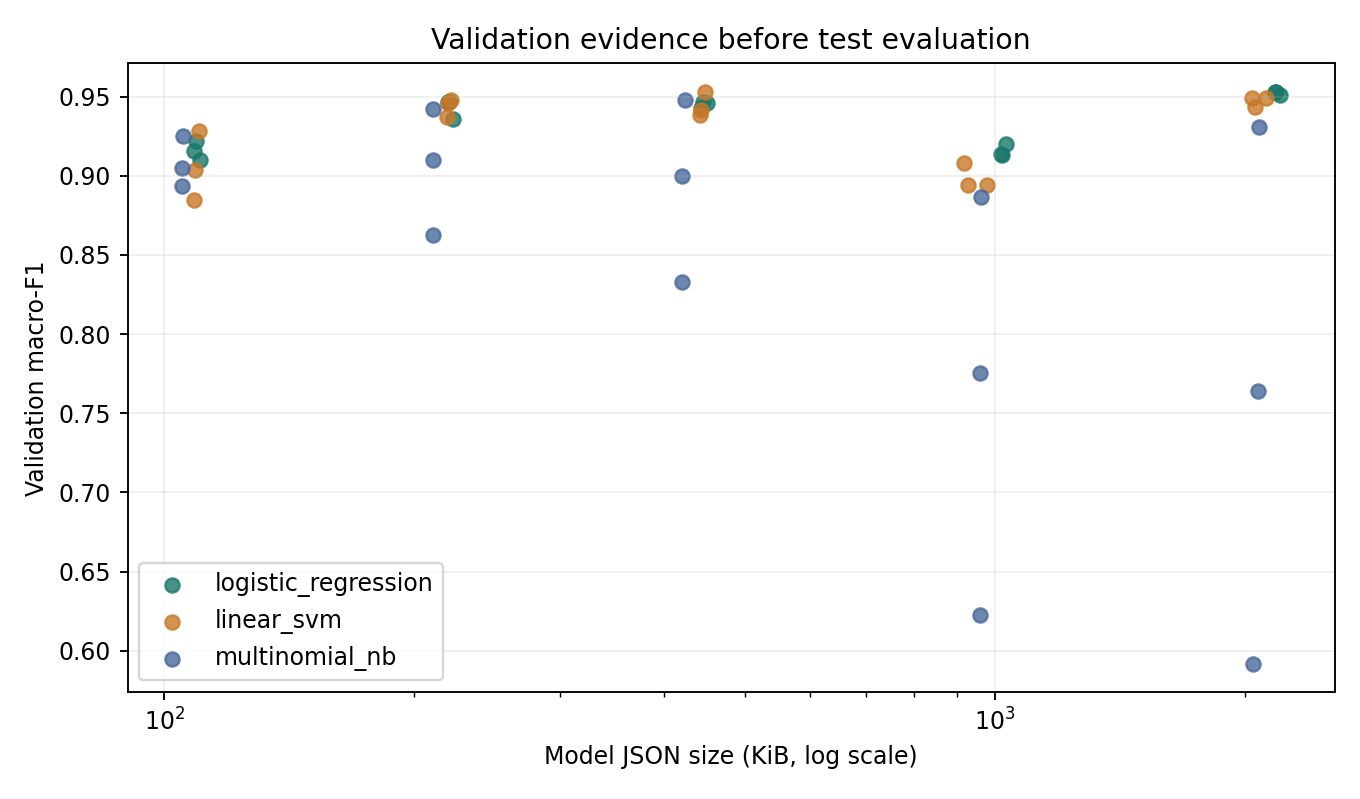

In [7]:
MODELS={BASELINE['trial_id']:BASE_MODEL};RECORDS=[]
for spec in SPECS:
    if spec['trial_id']==BASELINE['trial_id']:model,record=BASE_MODEL,BASE_RECORD
    else:model,record=lab.fit_trial(spec,ROWS,PARTS,CONFIG,RUN_META,DATA_HASH)
    MODELS[spec['trial_id']]=model;RECORDS.append(record)
    lab.write_csv(RUN/'trials.csv',RECORDS)
    print(record['trial_id'],record['family'],record['feature'],
          f"val F1={record['validation_macro_f1']:.4f}",
          f"JSON={record['model_json_bytes']/1024:.1f} KiB",'eligible=',record['eligible'])
TABLE=pd.DataFrame(RECORDS)
display(TABLE.sort_values('validation_macro_f1',ascending=False).head(12))
lab.plot_results(RECORDS,RUN)
display(Image(filename=str(RUN/'validation_tradeoff.png')))


## 8 Pilih model dengan aturan yang sudah dikunci
Model harus di bawah batas JSON. Dari kandidat yang macro-F1 validasinya dekat dengan kandidat eligible terbaik (selisih maksimal 0,01), pilih JSON terkecil. Ini memilih keseimbangan yang ditetapkan; hasilnya dapat berbeda dari model dengan skor absolut tertinggi. Model tetap dilatih pada train, tanpa refit setelah test.


In [8]:
SELECTED=lab.select_trial(RECORDS,CONFIG,RUN)
CHAMPION=MODELS[SELECTED['trial_id']]
SELECTED_SPEC=next(s for s in SPECS if s['trial_id']==SELECTED['trial_id'])
print(json.dumps(json.loads((RUN/'selection.json').read_text()),indent=2))


{
  "best_eligible_validation_macro_f1": 0.9528209773057146,
  "floor": 0.9428209773057146,
  "reason": "Among candidates under the JSON budget and within the tolerance of the best eligible validation macro-F1, choose the smallest model JSON; tie-break by validation macro-F1 then trial ID.",
  "selected": {
    "eligible": true,
    "family": "logistic_regression",
    "feature": "char_2048",
    "features": 2048,
    "fit_seconds": 0.3700058220001665,
    "model_json_bytes": 224664,
    "parameter_name": "C",
    "parameter_value": 4.0,
    "trial_id": "T030",
    "validation_accuracy": 0.9595959595959596,
    "validation_macro_f1": 0.9465345669735855
  },
  "test_used_for_selection": false
}


## 9 Evaluasi test satu kali setelah keputusan final
Jangan mengubah parameter berdasarkan tabel ini. Fungsi menolak evaluasi ulang pada run yang sama agar urutan kerja terlihat. Jika tujuan atau aturan penelitian diubah setelah melihat test, butuhkan evaluasi baru yang belum dipakai untuk memilih model.


In [9]:
TEST=lab.evaluate_test_once(CHAMPION,SELECTED,ROWS,PARTS,RUN)
print('Test macro-F1:',TEST['macro_f1'],'Akurasi:',TEST['accuracy'])
display(pd.DataFrame(TEST['confusion_matrix'],index=lab.LABELS.values(),columns=lab.LABELS.values()))
display(pd.DataFrame(TEST['per_class']).T)


Test macro-F1: 0.9114999881690408 Akurasi: 0.9299516908212561


,Ngoko,Ngoko Alus,Krama,Krama Alus
Ngoko,146,3,0,0
Ngoko Alus,7,49,0,2
Krama,4,0,141,4
Krama Alus,0,2,7,49


,precision,recall,f1-score,support
Ngoko,0.929936,0.979866,0.954248,149.000000
Ngoko Alus,0.907407,0.844828,0.875000,58.000000
Krama,0.952703,0.946309,0.949495,149.000000
Krama Alus,0.890909,0.844828,0.867257,58.000000
accuracy,0.929952,0.929952,0.929952,0.929952
macro avg,0.920239,0.903957,0.911500,414.000000
weighted avg,0.929506,0.929952,0.929248,414.000000


## 10 Telusuri satu prediksi hingga kontribusi fitur
Untuk setiap kelas, skor adalah intersep ditambah jumlah kontribusi fitur. CSV menampilkan n-gram, frekuensi, IDF, TF-IDF, dan kontribusi per kelas. SVM mengeluarkan decision score; softmax skor SVM bukan probabilitas yang terkalibrasi. Antarmuka PWA hanya menampilkan perkiraan label.


In [10]:
EXPORTED=lab.portable_model(CHAMPION,SELECTED_SPEC,RUN_META,DATA_HASH)
TRACE_ROWS,TRACE=lab.trace_sentence(CHAMPION,EXPORTED,'Kula nedha pecel dinten puniki.',RUN)
display(pd.DataFrame(TRACE_ROWS).head(20));print(json.dumps(TRACE,indent=2,ensure_ascii=False))


,feature_index,ngram,raw_count,idf,tfidf,contribution_Ngoko,contribution_Ngoko Alus,contribution_Krama,contribution_Krama Alus
0,719,din,1,5.256863,0.199323,0.073217,-0.055564,0.022197,-0.039850
1,1117,inten,1,5.199705,0.197156,-0.017277,-0.033992,0.045461,0.005808
2,802,en p,1,4.871201,0.184700,-0.041866,-0.021753,0.023835,0.039783
3,1116,inte,1,4.871201,0.184700,0.024759,-0.067320,0.074722,-0.032161
4,692,dha,1,4.794240,0.181782,0.082905,-0.059265,0.062862,-0.086502
5,1967,uni,1,4.757872,0.180403,-0.030995,-0.043700,0.090820,-0.016125
6,665,ce,1,4.688879,0.177787,0.037717,-0.005323,0.000898,-0.033292
7,778,el,1,4.656090,0.176544,0.000352,-0.019523,0.072943,-0.053773
8,177,ne,1,4.624341,0.175340,0.033060,-0.104027,0.129001,-0.058034
9,759,ec,1,4.563716,0.173041,-0.025760,0.058281,-0.062646,0.030124


{
  "text": "Kula nedha pecel dinten puniki.",
  "recognized_features": 62,
  "classes": [
    "Ngoko",
    "Ngoko Alus",
    "Krama",
    "Krama Alus"
  ],
  "intercepts": [
    1.574133112681319,
    -0.5326035180817908,
    0.3453750405188815,
    -1.3869046351184406
  ],
  "reconstructed_decision_scores": [
    0.5070171617498931,
    -2.1539410874511447,
    3.22293020774124,
    -1.5760062820400211
  ],
  "prediction": 2,
  "explanation": "Each class score equals its intercept plus the sum of feature contributions. These are model decisions, not contextual politeness judgments."
}


## 11 Ekspor bobot untuk browser dan ikat identitas rilis
PWA menerima JSON berisi bobot hasil pelatihan ini. Ekspor tidak melatih ulang. JavaScript mendukung ketiga classifier linear melalui penjumlahan bobot fitur. Kartu contoh dan kuis tetap bersumber dari dataset. Simpan Run ID dan versi rilis untuk mencocokkan aplikasi dengan eksperimen.


In [11]:
EXPORT=lab.export_pwa(ROOT,RUN,CHAMPION,SELECTED_SPEC,RUN_META,ROWS,DIALOGUES,PARTS)
print(json.dumps(EXPORT,indent=2))
print('Model browser:',ROOT/'docs/assets/model.json')
print('Pemeriksaan JavaScript dilakukan di halaman test.html pada browser sasaran.')


{
  "version": "fb594a9aa00dd6d7",
  "run_id": "20261107T082634Z_bb7bb1",
  "model": "T030_logistic_regression_char_2048",
  "classifier_type": "logistic_regression",
  "model_json_bytes": 224664,
  "static_files_bytes": 1003673,
  "code_commit": "df37386b29a48e37c7c9f735ece3f9a51c540316",
  "training_code_sha256": "a8b7367eaa708cb5318fdc89ecd2083b196c8769de19df2e1f5e81f6c365f63b",
  "dataset_sha256": "fadfdfe3473a5d2bb52112d93828e1bb762ed6d1d38dc3577d2928a7612f2e6c",
  "note": "Static file size differs from compressed transfer size, Joblib size, and browser memory."
}
Model browser: /content/basa-jawa-edge/docs/assets/model.json
Pemeriksaan JavaScript dilakukan di halaman test.html pada browser sasaran.


## 12 Unduh hasil sebelum runtime berakhir
ZIP pembaruan memuat seluruh folder docs/ dan bukti eksperimen kecil untuk GitHub. Model Python disimpan terpisah di run; checkpoint besar tidak diperlukan untuk PWA. Simpan juga notebook melalui File → Save a copy in GitHub atau unduh .ipynb dengan output. File runtime tidak otomatis tersimpan bersama notebook.


In [12]:
UPDATE_ZIP=lab.make_update_zip(ROOT,RUN)
print('ZIP pembaruan:',UPDATE_ZIP)
try:
    from google.colab import files
    files.download(str(UPDATE_ZIP))
except ImportError:
    print('Pemeriksaan lokal: unduh arsip ini secara manual.')


ZIP pembaruan: /content/basa-jawa-edge/runs/20261107T082634Z_bb7bb1/github_update.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13 Publikasikan dan uji PWA
Ekstrak ZIP pembaruan pada salinan repositori di Windows. Commit folder docs/ dan bukti run, lalu push melalui GitHub Desktop. Aktifkan Pages dari main dan /docs. Buka HTTPS, tunggu Siap offline, cocokkan Run ID/Versi dengan pwa_export.json, lalu buka test.html. Setelah itu lakukan pemeriksaan offline dan uji empat tugas kepada siswa.

Fine-tuning DistilBERT tersedia di notebook 02 sebagai eksperimen opsional. Checkpoint tersebut tidak otomatis dijalankan oleh PWA ringan.

Sumber platform: https://research.google.com/colaboratory/faq.html ; https://docs.github.com/en/pages/getting-started-with-github-pages/configuring-a-publishing-source-for-your-github-pages-site .
